# Lab GL4 — Neural Networks
Dense neural networks on the MNIST dataset (TensorFlow / Keras 3).

## Load the data and create train-test splits

In [4]:
# General imports
%matplotlib inline
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TF C++ info logs

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openml as oml
import tensorflow as tf
from tensorflow import keras

# Reproducibility (same seed for Python, NumPy and TensorFlow)
SEED = 0
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


In [5]:
# Download MNIST data (OpenML dataset 554). Takes a while the first time, then it is cached.
# Use OpenML's ARFF file instead of its parquet file: the parquet path goes through
# pandas' pyarrow extension types, which can raise ArrowKeyError ("type extension ... already defined").
os.environ["OPENML_SKIP_PARQUET"] = "true"

mnist = oml.datasets.get_dataset(554, download_data=True,
                                 download_qualities=False,
                                 download_features_meta_data=False)
X, y, _, _ = mnist.get_data(target=mnist.default_target_attribute)  # DataFrame / Series
X = X.to_numpy(dtype="float32").reshape(70000, 28, 28)
y = y.astype(int).to_numpy()   # labels '0'..'9' -> ints 0..9
print(X.shape, X.dtype, "| labels:", np.unique(y))

(70000, 28, 28) float32 | labels: [0 1 2 3 4 5 6 7 8 9]


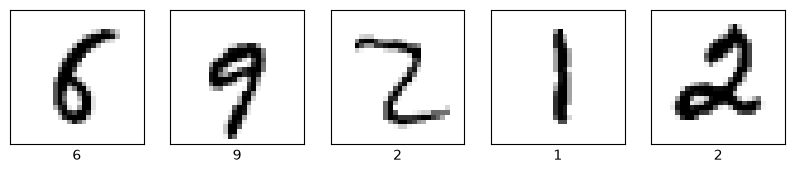

In [6]:
# Take some random examples
fig, axes = plt.subplots(1, 5, figsize=(10, 5))
for i in range(5):
    n = random.randint(0, 69999)
    axes[i].imshow(X[n], cmap=plt.cm.gray_r)
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].set_xlabel("{}".format(y[n]))
plt.show();

For MNIST there is a predefined train-test split of 60000-10000 (the first 60000 rows are the
official training set). The lab's comment says we don't shuffle, so we pass `shuffle=False`
explicitly — `train_test_split` shuffles by default otherwise.

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=60000, shuffle=False)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (60000, 28, 28) | test: (10000, 28, 28)


## Exercise 1: Preprocessing
- Normalize pixel values from integers in [0, 255] to floats in [0, 1].
- One-hot encode the labels.

In [8]:
x_train_normalized = X_train.astype("float32") / 255.0
x_test_normalized = X_test.astype("float32") / 255.0

y_train_encoded = keras.utils.to_categorical(y_train, num_classes=10)
y_test_encoded = keras.utils.to_categorical(y_test, num_classes=10)

print("pixel range:", x_train_normalized.min(), "->", x_train_normalized.max())
print("label", y_train[0], "->", y_train_encoded[0])

pixel range: 0.0 -> 1.0
label 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Exercise 2: Create a deep neural net model

Design choices:
- **Input shape**: each image is `(28, 28)`; a `Flatten` layer turns it into a 784-dimensional vector for the dense layers.
- **2 dense layers**: a hidden ReLU layer (`layer_1_units`) and the output layer (`layer_2_units`, default 10 — one unit per class).
- **Regularization**: a `Dropout` layer after the hidden layer.
- **Last-layer activation**: `softmax`, so the 10 outputs form a probability distribution over the classes.
- **Loss**: `categorical_crossentropy` (labels are one-hot). **Optimizer**: Adam with a configurable learning rate.

In [9]:
### Create and compile a 'deep' neural net
def create_model(layer_1_units=32, layer_2_units=10, learning_rate=0.001, dropout_rate=0.3):
    model = keras.Sequential([
        keras.Input(shape=(28, 28)),
        keras.layers.Flatten(),
        keras.layers.Dense(layer_1_units, activation="relu"),
        keras.layers.Dropout(dropout_rate),
        keras.layers.Dense(layer_2_units, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

create_model().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

## Exercise 3: Create a training function
Keras' `validation_split` holds out the **last** fraction of the training data as the validation set.

In [10]:
def train_model(model, X, y, validation_split=0.1, epochs=10, batch_size=None,
                callbacks=None, verbose=0):
    """
    model: the model to train
    X, y: the training data and labels
    validation_split: the percentage of data set aside for the validation set
    epochs: the number of epochs to train for
    batch_size: the batch size for minibatch SGD
    """
    history = model.fit(X, y,
                        validation_split=validation_split,
                        epochs=epochs,
                        batch_size=batch_size,
                        callbacks=callbacks,
                        verbose=verbose)
    h = history.history
    print(f"Epochs run: {len(history.epoch)}")
    print(f"  train loss: {h['loss'][-1]:.4f} | train accuracy: {h['accuracy'][-1]:.4f}")
    print(f"  val   loss: {h['val_loss'][-1]:.4f} | val   accuracy: {h['val_accuracy'][-1]:.4f}")
    if callbacks:  # with early stopping, the restored weights are from the best epoch
        best = int(np.argmax(h["val_accuracy"]))
        print(f"  best val accuracy: {h['val_accuracy'][best]:.4f} (epoch {best + 1})")
    return history

## Exercise 4: Evaluate the model
Learning rate 0.003, 50 epochs, batch size 4000, validation set = 20% of the training data, defaults otherwise.

In [11]:
# Helper plotting function
#
# history: the history object returned by the fit function
# list_of_metrics: the metrics to plot
def plot_curve(history, list_of_metrics, title=None):
    plt.figure()
    plt.xlabel("Epoch")
    plt.ylabel("Value")
    if title:
        plt.title(title)

    epochs = history.epoch
    hist = pd.DataFrame(history.history)

    for m in list_of_metrics:
        x = hist[m]
        plt.plot(epochs[1:], x[1:], label=m, lw=2)

    plt.legend()
    plt.show()

Epochs run: 50
  train loss: 0.2442 | train accuracy: 0.9255
  val   loss: 0.1604 | val   accuracy: 0.9534


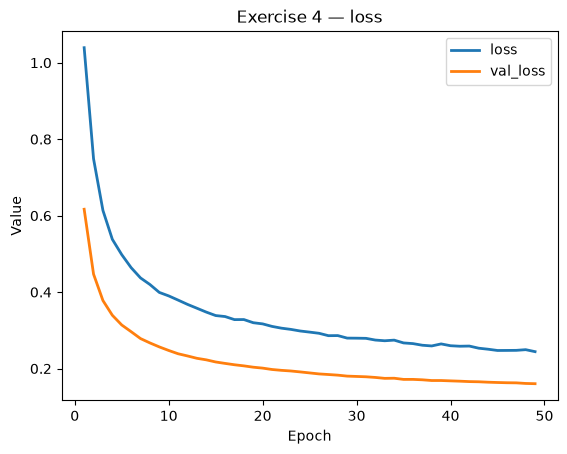

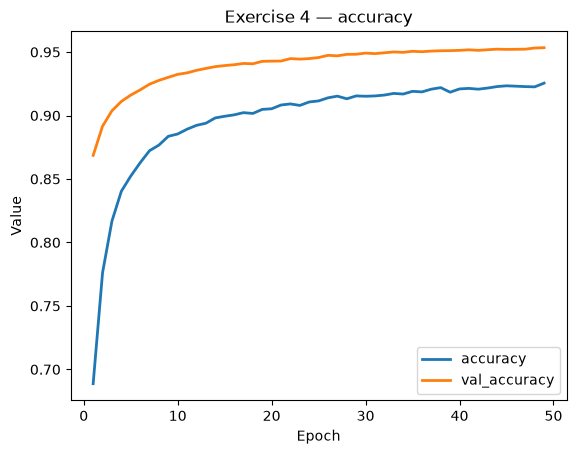

In [12]:
keras.utils.set_random_seed(SEED)
model = create_model(learning_rate=0.003)
history = train_model(model, x_train_normalized, y_train_encoded,
                      validation_split=0.2, epochs=50, batch_size=4000)

plot_curve(history, ["loss", "val_loss"], title="Exercise 4 — loss")
plot_curve(history, ["accuracy", "val_accuracy"], title="Exercise 4 — accuracy")

In [13]:
test_loss, test_acc = model.evaluate(x_test_normalized, y_test_encoded, verbose=0)
print(f"Exercise 4 baseline — test loss: {test_loss:.4f} | test accuracy: {test_acc:.4f}")

Exercise 4 baseline — test loss: 0.1635 | test accuracy: 0.9529


**Observation**: with only 32 hidden units the model underfits slightly. Validation accuracy can sit
*above* training accuracy because dropout is active during training but disabled at evaluation.

## Exercise 5: Optimize the model

Approach — manual grid search over the three required hyperparameters:
- **Number of hidden layers** (1 → 3)
- **Nodes per layer** (128 → 1024)
- **Number of dropout layers and dropout rate** (0 → one per hidden layer; rate 0.2 → 0.4)

Selection is done on the **validation set only** (20% of training data); the test set is used once, on the
selected model. Training uses batch size 256 with early stopping on validation accuracy
(patience 5, best weights restored), max 50 epochs, learning rate 0.001.

In [14]:
def create_deep_model(hidden_units=(256, 128), dropout_rates=(0.2, 0.2), learning_rate=0.001):
    """
    hidden_units:  one entry per hidden Dense layer (number of nodes).
    dropout_rates: one entry per hidden layer; 0 / None means no Dropout layer after that layer.
    """
    assert len(dropout_rates) == len(hidden_units), "one dropout rate per hidden layer"
    layers = [keras.Input(shape=(28, 28)), keras.layers.Flatten()]
    for units, rate in zip(hidden_units, dropout_rates):
        layers.append(keras.layers.Dense(units, activation="relu"))
        if rate:
            layers.append(keras.layers.Dropout(rate))
    layers.append(keras.layers.Dense(10, activation="softmax"))

    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

In [15]:
# Candidate configurations: (name, hidden_units, dropout_rates)
configs = [
    ("1x128, no dropout",       (128,),           (0,)),
    ("1x512, drop 0.2",         (512,),           (0.2,)),
    ("2x256, drop 0.2 (1 layer)", (256, 256),     (0.2, 0)),
    ("2x256, drop 0.2 (both)",  (256, 256),       (0.2, 0.2)),
    ("512-256, drop 0.3",       (512, 256),       (0.3, 0.3)),
    ("1024-512, drop 0.4",      (1024, 512),      (0.4, 0.4)),
    ("512-256-128, drop 0.3",   (512, 256, 128),  (0.3, 0.3, 0.3)),
    ("512-256-128, drop 0.2",   (512, 256, 128),  (0.2, 0.2, 0.2)),
]

early_stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5,
                                           restore_best_weights=True)
results, trained = [], {}
for name, units, drops in configs:
    print(f"\n=== {name} ===")
    keras.utils.set_random_seed(SEED)
    m = create_deep_model(units, drops, learning_rate=0.001)
    h = train_model(m, x_train_normalized, y_train_encoded,
                    validation_split=0.2, epochs=50, batch_size=256,
                    callbacks=[early_stop])
    best_val = max(h.history["val_accuracy"])
    results.append({"config": name,
                    "hidden_layers": len(units),
                    "nodes": "-".join(map(str, units)),
                    "dropout_layers": sum(1 for d in drops if d),
                    "dropout_rate": max(drops),
                    "params": m.count_params(),
                    "epochs": len(h.epoch),
                    "best_val_accuracy": best_val})
    trained[name] = (m, h)

results_df = pd.DataFrame(results).sort_values("best_val_accuracy", ascending=False)
results_df.reset_index(drop=True)


=== 1x128, no dropout ===
Epochs run: 40
  train loss: 0.0017 | train accuracy: 1.0000
  val   loss: 0.1037 | val   accuracy: 0.9766
  best val accuracy: 0.9772 (epoch 35)

=== 1x512, drop 0.2 ===
Epochs run: 30
  train loss: 0.0053 | train accuracy: 0.9984
  val   loss: 0.0832 | val   accuracy: 0.9804
  best val accuracy: 0.9822 (epoch 25)

=== 2x256, drop 0.2 (1 layer) ===
Epochs run: 28
  train loss: 0.0127 | train accuracy: 0.9956
  val   loss: 0.0940 | val   accuracy: 0.9814
  best val accuracy: 0.9822 (epoch 23)

=== 2x256, drop 0.2 (both) ===
Epochs run: 14
  train loss: 0.0241 | train accuracy: 0.9923
  val   loss: 0.0906 | val   accuracy: 0.9756
  best val accuracy: 0.9790 (epoch 9)

=== 512-256, drop 0.3 ===
Epochs run: 26
  train loss: 0.0162 | train accuracy: 0.9948
  val   loss: 0.0967 | val   accuracy: 0.9809
  best val accuracy: 0.9814 (epoch 21)

=== 1024-512, drop 0.4 ===
Epochs run: 16
  train loss: 0.0240 | train accuracy: 0.9921
  val   loss: 0.0832 | val   accurac

,config,hidden_layers,nodes,dropout_layers,dropout_rate,params,epochs,best_val_accuracy
0,"512-256-128, drop 0.2",3,512-256-128,3,0.2,567434,24,0.982500
1,"1x512, drop 0.2",1,512,1,0.2,407050,30,0.982250
2,"2x256, drop 0.2 (1 layer)",2,256-256,1,0.2,269322,28,0.982250
3,"1024-512, drop 0.4",2,1024-512,2,0.4,1333770,16,0.981833
4,"512-256, drop 0.3",2,512-256,2,0.3,535818,26,0.981417
5,"512-256-128, drop 0.3",3,512-256-128,3,0.3,567434,17,0.979583
6,"2x256, drop 0.2 (both)",2,256-256,2,0.2,269322,14,0.979000
7,"1x128, no dropout",1,128,0,0.0,101770,40,0.977167


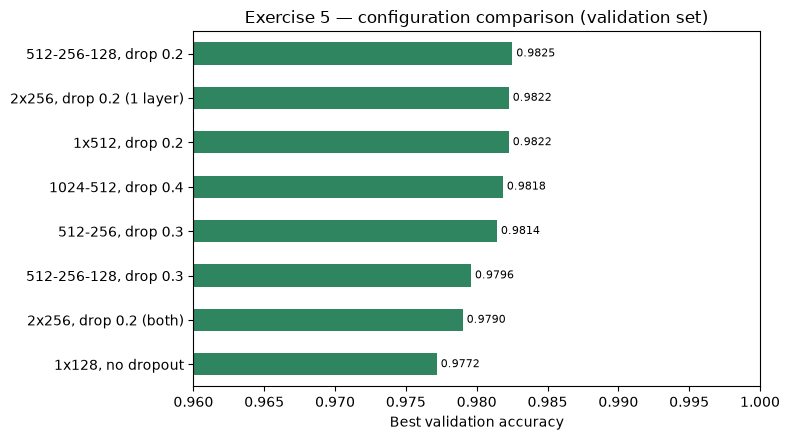

In [16]:
# Validation accuracy per configuration
ax = results_df.sort_values("best_val_accuracy").plot.barh(
    x="config", y="best_val_accuracy", legend=False, figsize=(8, 4.5), color="#2F855F")
ax.set_xlim(0.96, 1.0)
ax.set_xlabel("Best validation accuracy")
ax.set_ylabel("")
ax.set_title("Exercise 5 — configuration comparison (validation set)")
for p in ax.patches:
    ax.annotate(f"{p.get_width():.4f}", (p.get_width(), p.get_y() + p.get_height() / 2),
                xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
plt.tight_layout()
plt.show()

Selected configuration: 512-256-128, drop 0.2


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_9 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,702,304 (6.49 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,134,870 (4.33 MB)

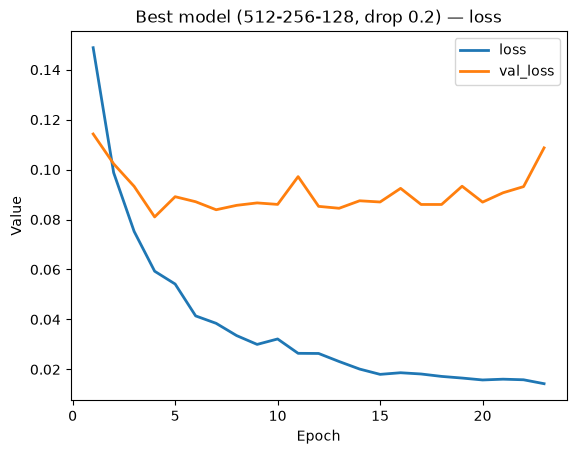

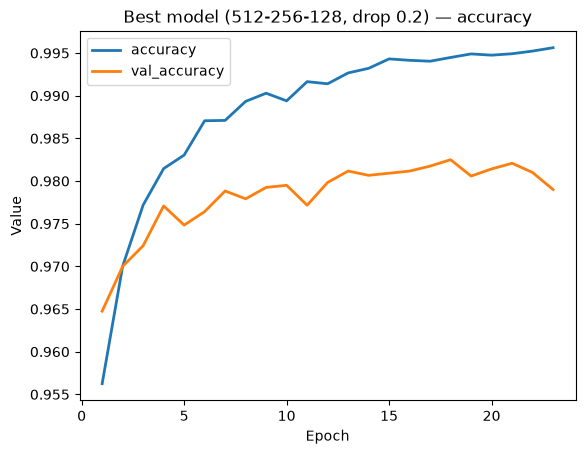


Baseline (Ex. 4) test accuracy: 0.9529
Tuned    (Ex. 5) test accuracy: 0.9816  (loss 0.0769)


In [17]:
# Final evaluation of the configuration selected on the validation set
best_name = results_df.iloc[0]["config"]
best_model, best_history = trained[best_name]
print("Selected configuration:", best_name)
best_model.summary()

plot_curve(best_history, ["loss", "val_loss"], title=f"Best model ({best_name}) — loss")
plot_curve(best_history, ["accuracy", "val_accuracy"], title=f"Best model ({best_name}) — accuracy")

best_test_loss, best_test_acc = best_model.evaluate(x_test_normalized, y_test_encoded, verbose=0)
print(f"\nBaseline (Ex. 4) test accuracy: {test_acc:.4f}")
print(f"Tuned    (Ex. 5) test accuracy: {best_test_acc:.4f}  (loss {best_test_loss:.4f})")
assert best_test_acc >= 0.96, "Target of 96% test accuracy not reached"

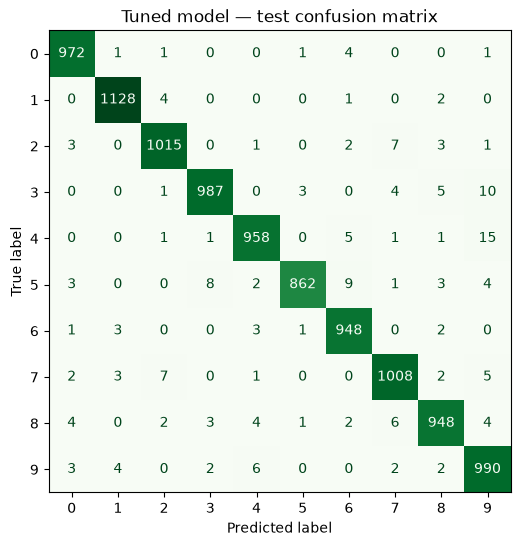

184 misclassified test images out of 10000


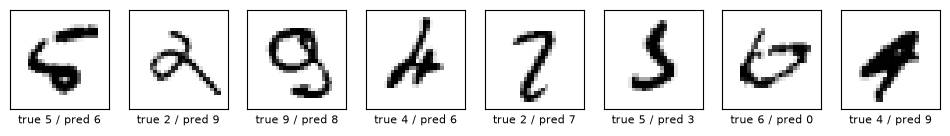

In [18]:
# Where does the tuned model still make mistakes?
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = best_model.predict(x_test_normalized, verbose=0).argmax(axis=1)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_title("Tuned model — test confusion matrix")
plt.show()

wrong = np.flatnonzero(y_pred != y_test)
print(f"{len(wrong)} misclassified test images out of {len(y_test)}")
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, wrong[:8]):
    ax.imshow(X_test[i], cmap=plt.cm.gray_r)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(f"true {y_test[i]} / pred {y_pred[i]}", fontsize=8)
plt.show()

## Conclusions
- **Width + batch size drive the gain**: the baseline (32 units, batch 4000) underfits at ~95%. Widening the hidden layer to 128–512 units and using batch 256 (~16× more gradient updates per epoch) lifts every configuration to ~98%.
- **Depth barely matters**: 1, 2 and 3 hidden layers all land within ~0.4% validation accuracy of each other. A single 512-unit layer was best, so extra layers add parameters without benefit for dense nets on MNIST.
- **Dropout**: the no-dropout model reaches 100% training accuracy (clear overfitting) and has the lowest validation accuracy. A rate of 0.2–0.3 works best; 0.4 on wide layers is slightly worse.
- Differences between the top configurations (~0.1–0.4%) are close to run-to-run noise. A fair ranking would average several seeds or use cross-validation.
- The tuned model clears the **96% target** (~98% on test). Going much higher would need a CNN.